## TDM TNA

## 1. Arrondi et troncature:

In [1]:
import numpy as np

def arrondi(val, MAXI, B):
    delta_q = MAXI / (2**B - 1)

    val = np.asarray(val)
    val = np.clip(val, -MAXI, MAXI)

    # arrondi
    q = np.round(val / delta_q) * delta_q

    return q

In [3]:
print(arrondi(np.array([-1.0, -0.5, 0.0, 0.5, 1.0]), 1.0, 3))

[-1.         -0.57142857  0.          0.57142857  1.        ]


In [2]:
def troncature(val, MAXI, B):
    delta_q = MAXI / (2**B - 1)

    val = np.asarray(val)

    val = np.clip(val, -MAXI, MAXI)

    # val tronquée
    q = np.floor(val / delta_q) * delta_q

    return q

In [6]:
val = np.array([-1.0, -0.7, -0.2, 0.1, 0.37, 0.8, 1.0])

MAXI = 1
B = 3

print("Original :", val)
print("Arrondi  :", arrondi(val, MAXI, B))
print("Tronqué  :", troncature(val, MAXI, B))

Original : [-1.   -0.7  -0.2   0.1   0.37  0.8   1.  ]
Arrondi  : [-1.         -0.71428571 -0.14285714  0.14285714  0.42857143  0.85714286
  1.        ]
Tronqué  : [-1.         -0.71428571 -0.28571429  0.          0.28571429  0.71428571
  1.        ]


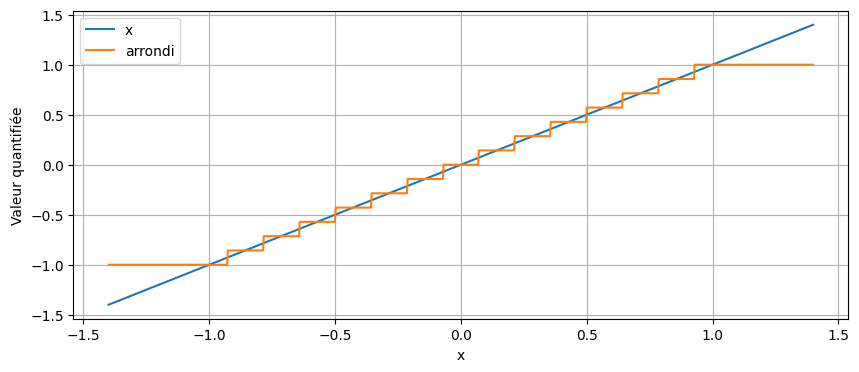

In [7]:
import matplotlib.pyplot as plt

x = np.linspace(-1.4, 1.4, 1000)

MAXI = 1
B = 3

x_arr = arrondi(x, MAXI, B)
x_tronc = troncature(x, MAXI, B)

plt.figure(figsize=(10, 4))

plt.plot(x, x, label="x")
plt.plot(x, x_arr, label="arrondi")

plt.xlabel("x")
plt.ylabel("Valeur quantifiée")
plt.grid()
plt.legend()

plt.show()

## 2. Structure bi-quad:

In [8]:
import numpy as np

def bi_quad(B, A, x):
    B = np.asarray(B)
    A = np.asarray(A)
    x = np.asarray(x)

    y = np.zeros(len(x))

    for n in range(len(x)):

        # terme courant
        y[n] = B[0] * x[n]

        # termes n-1
        if n >= 1:
            y[n] += B[1] * x[n-1]
            y[n] -= A[1] * y[n-1]

        # termes n-2
        if n >= 2:
            y[n] += B[2] * x[n-2]
            y[n] -= A[2] * y[n-2]

        # division par a0
        y[n] /= A[0]

    return y

In [10]:
from scipy.signal import lfilter

B = [0.2, 0.4, 0.2]
A = [1.0, -0.3, 0.1]

x = np.zeros(30)
x[0] = 1


y_maison = bi_quad(B, A, x)
y_ref = lfilter(B, A, x)

print(y_maison)
print(y_ref)

[ 2.00000000e-01  4.60000000e-01  3.18000000e-01  4.94000000e-02
 -1.69800000e-02 -1.00340000e-02 -1.31220000e-03  6.09740000e-04
  3.14142000e-04  3.32686000e-05 -2.14336200e-05 -9.75694600e-06
 -7.83721800e-07  7.40578060e-07  3.00545598e-07  1.61058734e-08
 -2.52227978e-08 -9.17742667e-09 -2.30948224e-10  8.48458200e-10
  2.77632282e-10 -1.55613528e-12 -2.82300688e-11 -8.31340712e-12
  3.28984747e-13  9.30036136e-13  2.46112366e-13 -1.91699038e-14
 -3.03622077e-14 -7.19167195e-15]
[ 2.00000000e-01  4.60000000e-01  3.18000000e-01  4.94000000e-02
 -1.69800000e-02 -1.00340000e-02 -1.31220000e-03  6.09740000e-04
  3.14142000e-04  3.32686000e-05 -2.14336200e-05 -9.75694600e-06
 -7.83721800e-07  7.40578060e-07  3.00545598e-07  1.61058734e-08
 -2.52227978e-08 -9.17742667e-09 -2.30948224e-10  8.48458200e-10
  2.77632282e-10 -1.55613528e-12 -2.82300688e-11 -8.31340712e-12
  3.28984747e-13  9.30036136e-13  2.46112366e-13 -1.91699038e-14
 -3.03622077e-14 -7.19167195e-15]


In [12]:
print(np.allclose(y_maison, y_ref))

True


In [11]:
y = bi_quad(B, A, x)

print(y)

[ 2.00000000e-01  4.60000000e-01  3.18000000e-01  4.94000000e-02
 -1.69800000e-02 -1.00340000e-02 -1.31220000e-03  6.09740000e-04
  3.14142000e-04  3.32686000e-05 -2.14336200e-05 -9.75694600e-06
 -7.83721800e-07  7.40578060e-07  3.00545598e-07  1.61058734e-08
 -2.52227978e-08 -9.17742667e-09 -2.30948224e-10  8.48458200e-10
  2.77632282e-10 -1.55613528e-12 -2.82300688e-11 -8.31340712e-12
  3.28984747e-13  9.30036136e-13  2.46112366e-13 -1.91699038e-14
 -3.03622077e-14 -7.19167195e-15]


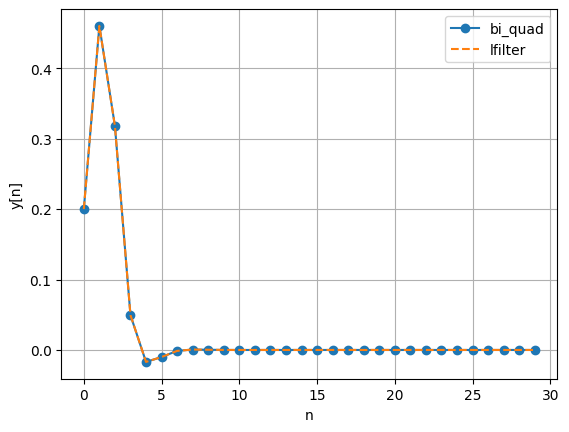

In [13]:
import matplotlib.pyplot as plt

plt.plot(y_maison, 'o-', label='bi_quad')
plt.plot(y_ref, '--', label='lfilter')

plt.xlabel("n")
plt.ylabel("y[n]")
plt.grid()
plt.legend()
plt.show()

In [14]:
import numpy as np

def gain_coherent(B, A):
    return np.sum(B) / np.sum(A)

In [15]:
B = [0.2, 0.4, 0.2]
A = [1.0, -0.3, 0.1]

G = gain_coherent(B, A)

print(G)

1.0000000000000002


Puissance entrée : 0.9885384126407886
Puissance sortie : 0.3508307507749288


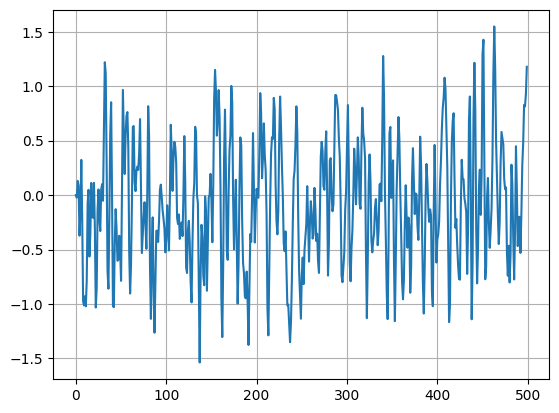

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# bruit blanc
x = np.random.randn(10000)

# filtrage
y = bi_quad(B, A, x)

# puissance mesurée
Px = np.mean(x**2)
Py = np.mean(y**2)

print("Puissance entrée :", Px)
print("Puissance sortie :", Py)

plt.plot(y[:500])
plt.grid()
plt.show()